In [2]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
from pathlib import Path
from PIL import Image
import sys


augmentation_path = Path.cwd() / "04_modeling"
sys.path.append(str(augmentation_path))

from utils.augmentations import (
    JointCompose, JointToTensor, JointResize, JointRandomHorizontalFlip,
    JointRandomAffine, JointColorJitter, RandomBlur, RandomNoise,
    RandomCoarseDropout, OneOf, JointRandomScale, JointRandomCrop
)

data_dir = Path('/Volumes/SanDisk/Ablage/cityscapes')
img_dir = data_dir / "leftImg8bit" / "train"
label_dir = data_dir / "gtFine" / "train"

In [3]:
# 1. Bild & Label suchen und laden
city_folders = list(img_dir.glob("*"))

if not city_folders:
    print("ACHTUNG: Keine Ordner gefunden.")
else:
    first_city = city_folders[0]
    img_path = sorted(first_city.glob("*_leftImg8bit.png"))[0]
    label_name = img_path.name.replace("_leftImg8bit.png", "_gtFine_labelTrainIds.png")
    label_path = label_dir / first_city.name / label_name

    print(f"Lade Bild: {img_path}")

    # Bild laden -> PIL
    image_cv = cv2.imread(str(img_path))
    image_cv = cv2.cvtColor(image_cv, cv2.COLOR_BGR2RGB)
    image = Image.fromarray(image_cv)

    # Label laden -> PIL
    mask_cv = cv2.imread(str(label_path), cv2.IMREAD_UNCHANGED)
    mask = Image.fromarray(mask_cv)

    # --- 2. Augmentierungen definieren ---

    # Definition der vollen Pipeline (wie in deinem Snippet, ohne ToTensor für Visualisierung)
    full_pipeline_transforms = [
        JointRandomScale(scale_range=(0.5, 1.0)),
        JointRandomCrop(size=(512, 1024)),
        JointRandomHorizontalFlip(p=0.5),
        JointRandomAffine(degrees=30, translate=(0.1, 0.1), scale=(0.8, 1.2), p=1.0),
        OneOf([
            RandomNoise(intensity=50),
            RandomBlur(),
        ], p=0.3),
        OneOf([
            JointColorJitter(brightness=0.5, contrast=0.6, saturation=0.5, hue=0.2),
        ], p=0.5),
        RandomCoarseDropout(max_holes=10, max_height=64, max_width=64, p=1.0)
    ]

    augmentations_to_test = [
        # A. Baseline
        (
            "Original (Nur Resize 512x1024)",
            JointCompose([JointResize(size=(512, 1024))])
        ),
          (
            "1. Scale & Crop",
            JointCompose([
                JointRandomScale(scale_range=(0.5, 1.0)),
                JointRandomCrop(size=(512, 1024))
            ])
        ),
        (
            "2. Horizontal Flip",
            JointCompose([
                JointResize(size=(512, 1024)),
                JointRandomHorizontalFlip(p=1.0)
            ])
        ),
        (
            "3. Affine (Drehung/Shift/Scale)",
            JointCompose([
                JointResize(size=(512, 1024)),
                JointRandomAffine(degrees=30, translate=(0.1, 0.1), scale=(0.8, 1.2), p=1.0)
            ])
        ),
        (
            "4. Noise / Blur (Störungen)",
            JointCompose([
                JointResize(size=(512, 1024)),
                OneOf([
                    RandomNoise(intensity=50),
                    RandomBlur(),
                ], p=1.0)
            ])
        ),
        (
            "5. Color Jitter (Farbe)",
            JointCompose([
                JointResize(size=(512, 1024)),
                JointColorJitter(brightness=0.5, contrast=0.6, saturation=0.5, hue=0.2)
            ])
        ),
        (
            "6. Coarse Dropout (Löcher)",
            JointCompose([
                JointResize(size=(512, 1024)),
                RandomCoarseDropout(max_holes=10, max_height=64, max_width=64, p=1.0)
            ])
        ),

        # C. Alles zusammen
        (
            "FULL PIPELINE (Training Config)",
            JointCompose(full_pipeline_transforms)
        )
    ]

Lade Bild: /Volumes/SanDisk/Ablage/cityscapes/leftImg8bit/train/jena/jena_000000_000019_leftImg8bit.png


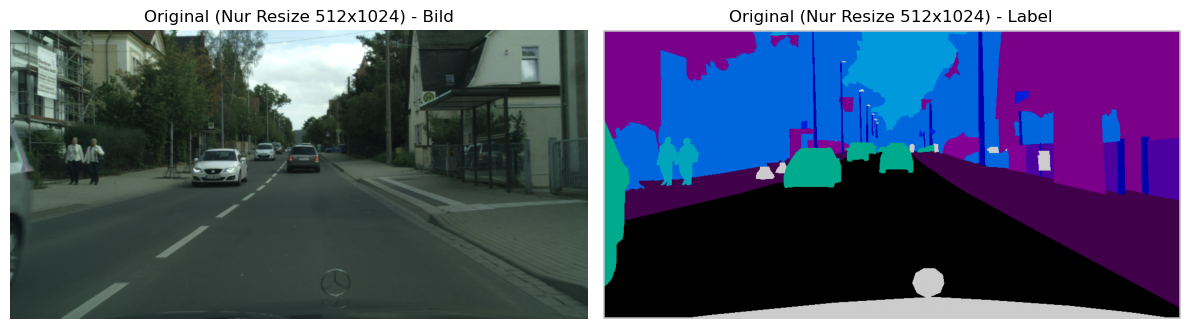

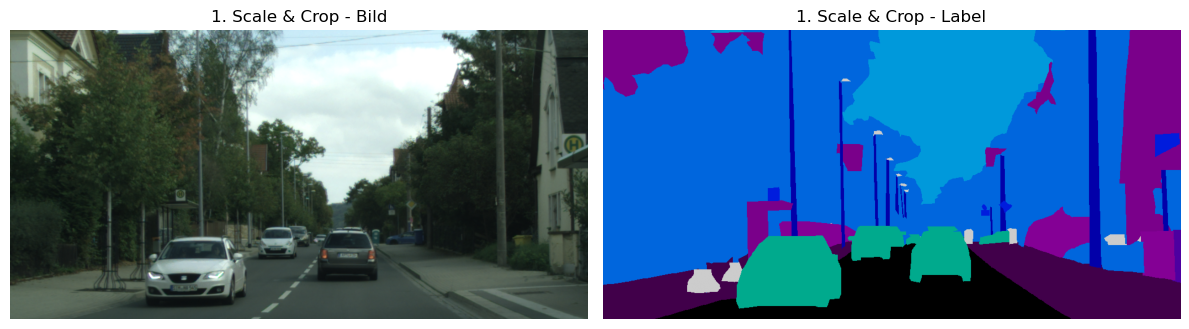

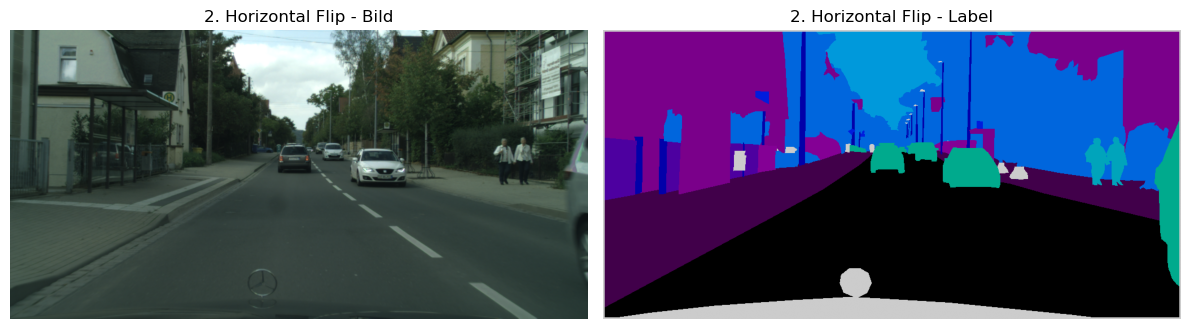

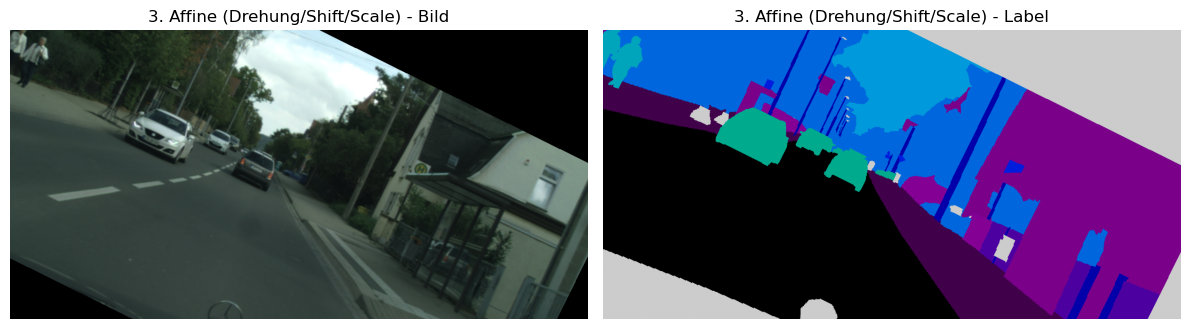

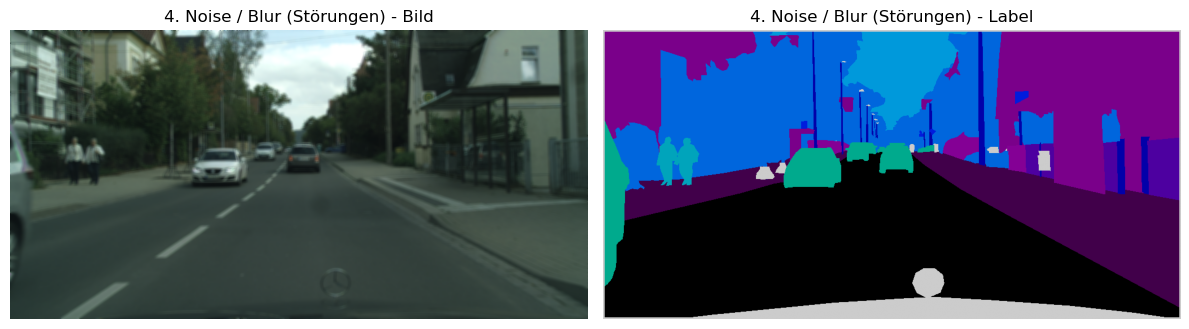

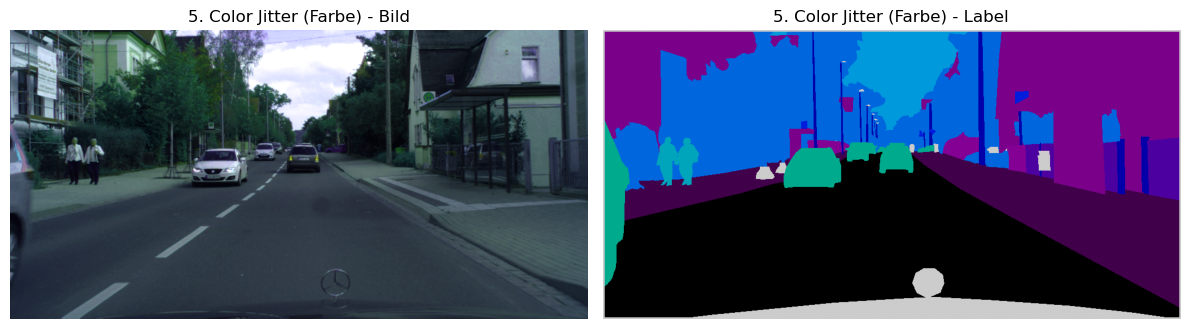

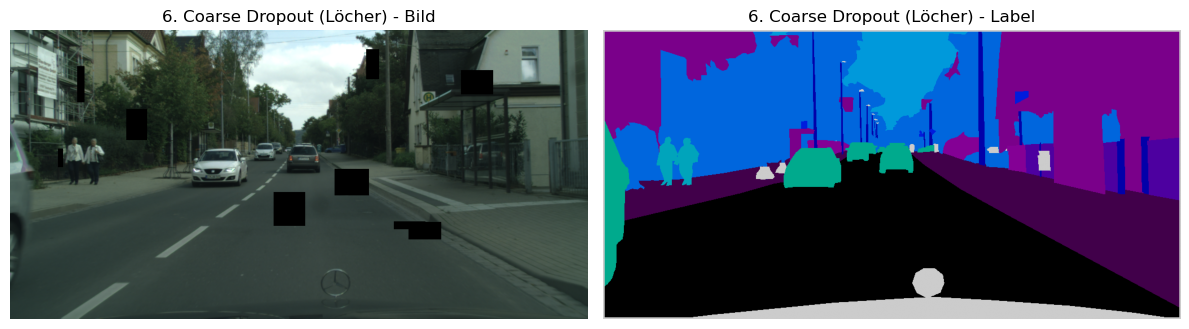

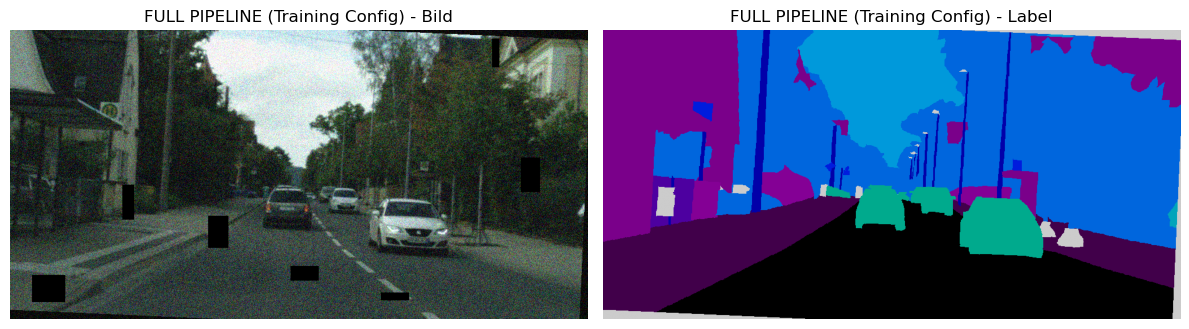

In [14]:
def visualize(image, mask, transforms_list):
    for title, transform in transforms_list:
        aug_img, aug_mask = transform(image.copy(), mask.copy())

        aug_img = np.array(aug_img)
        aug_mask = np.array(aug_mask)

        # Plotting
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        # Bild
        axes[0].imshow(aug_img)
        axes[0].set_title(f"{title} - Bild")
        axes[0].axis("off")

        axes[1].imshow(aug_mask, cmap='nipy_spectral', vmin=0, vmax=33)
        axes[1].set_title(f"{title} - Label")
        axes[1].axis("off")

        plt.tight_layout()
        plt.show()

# Ausführen
visualize(image, mask, augmentations_to_test)